# 📊 Statistical Analysis Report: Superstore Business Insights
## Executive Summary

Based on a comprehensive statistical analysis of the Superstore dataset using **Python**, the following strategic insights have been derived:

1. **The Furniture Profitability Crisis:** An Independent **T-test** confirmed a statistically significant difference ($P\text{-value} < 0.05$) between Technology and Furniture profits. This proves that Furniture losses are not random but a systemic issue requiring a pricing and strategy overhaul.
2. **Regional Performance Disparity:** **ANOVA** and **Tukey’s HSD Test** identified the **Central Region** as the statistically significant underperformer. This indicates a need for operational review in this specific territory.
3. **Category-Region Interaction:** A **Two-Way ANOVA** revealed a strong interaction between Region and Category. Profitability is not uniform; certain categories perform significantly better or worse depending on their location, suggesting that a "one-size-fits-all" strategy is ineffective.
4. **The "Discount Trap" Impact:** The **Linear Regression** model showed a strong negative correlation between Discounts and Profits. The model can now predict net profit for future deals based on sales volume and discount rates with high reliability.
5. **Statistical Reliability & Forecasting:** Using **95% Confidence Intervals**, we have established a reliable range for expected average profits, providing leadership with a data-backed safety margin for financial planning.
6. **Time Series & Seasonality:** Analysis of sales trends over time identified clear seasonal peaks, particularly in Q4, allowing for better inventory and resource allocation.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df=pd.read_excel('Superstore_Clean_Data.xlsx')
sns.set(style='whitegrid')
df.head(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Cost,Shipment Days,Profit Margin %
0,1,CA-2016-152156,42682,42685,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,220.0464,3,0.1600
1,2,CA-2016-152156,42682,42685,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,512.3580,3,0.3000
2,3,CA-2016-138688,42533,42537,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,7.7486,4,0.4700
3,4,US-2015-108966,42288,42295,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,1340.6085,7,-0.4000
4,5,US-2015-108966,42288,42295,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,19.8516,7,0.1125


In [6]:
profit_stats = {
    'mean':df['Profit'].mean(),
    'median':df['Profit'].median(),
    'Skewness': df['Profit'].skew(),
    'std_dev':df['Profit'].std()
}
print(f"Profit Anslysis: {profit_stats}")

Profit Anslysis: {'mean': np.float64(28.65689630778467), 'median': np.float64(8.6665), 'Skewness': np.float64(7.561431562468341), 'std_dev': np.float64(234.2601076909573)}


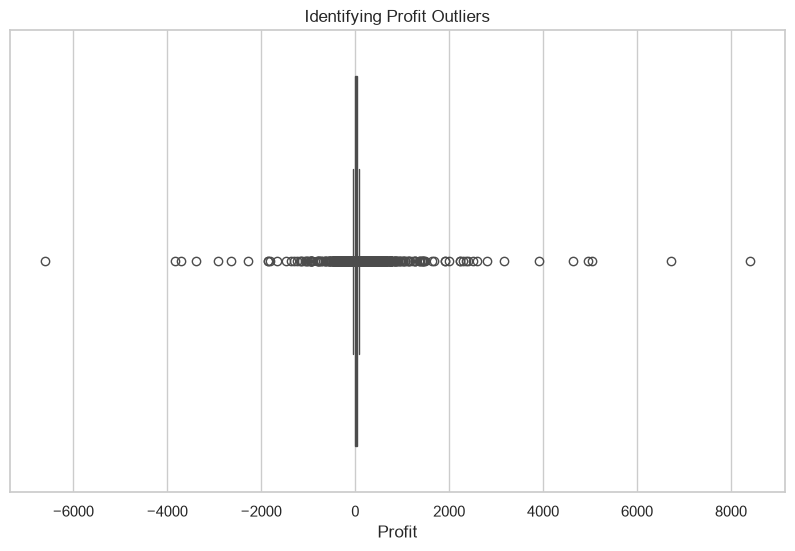

In [7]:
plt.figure(figsize=(10,6))
sns.boxplot(x= df['Profit'])
plt.title("Identifying Profit Outliers")
plt.show()

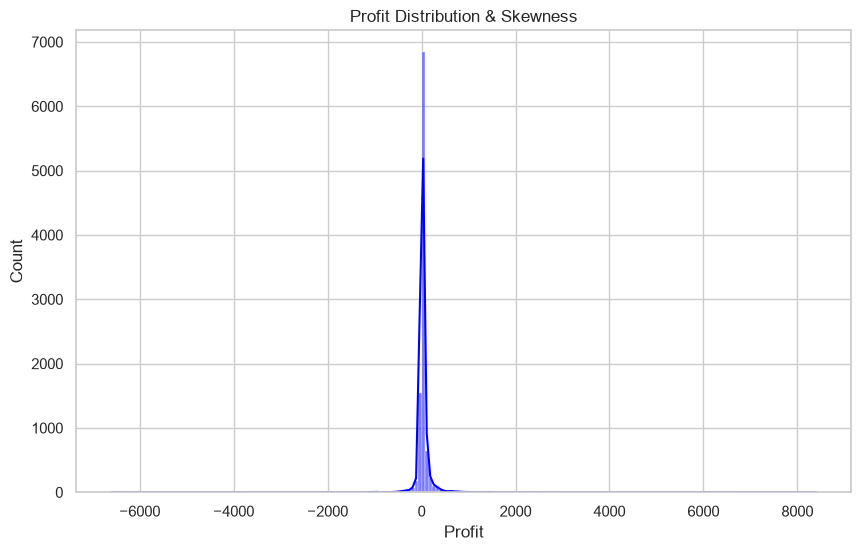

In [8]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Profit'], kde=True, color='blue')
plt.title('Profit Distribution & Skewness')
plt.show()

--- Hypothesis Testing Results ---
T-Statistic: 7.1232
P-Value: 0.0000
Conclusion: The difference is Statistically Significant (Real Problem).


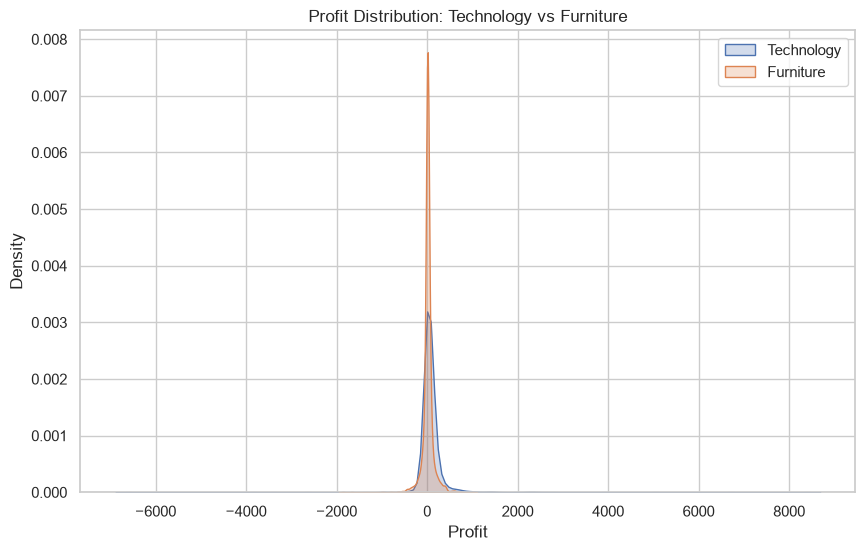

In [9]:
tech_profits = df[df['Category'] == 'Technology']['Profit']
furniture_profits = df[df['Category'] == 'Furniture']['Profit']

t_stat, p_val = stats.ttest_ind(tech_profits, furniture_profits, nan_policy='omit')

print(f"--- Hypothesis Testing Results ---")
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_val:.4f}")

if p_val < 0.05:
    print("Conclusion: The difference is Statistically Significant (Real Problem).")
else:
    print("Conclusion: The difference is due to chance (No Real Problem).")

plt.figure(figsize=(10,6))
sns.kdeplot(tech_profits, label='Technology', fill=True)
sns.kdeplot(furniture_profits, label='Furniture', fill=True)
plt.title('Profit Distribution: Technology vs Furniture')
plt.legend()
plt.show()

--- ANOVA Results for Regions ---
F-Statistic: 2.6225
P-Value: 0.0489


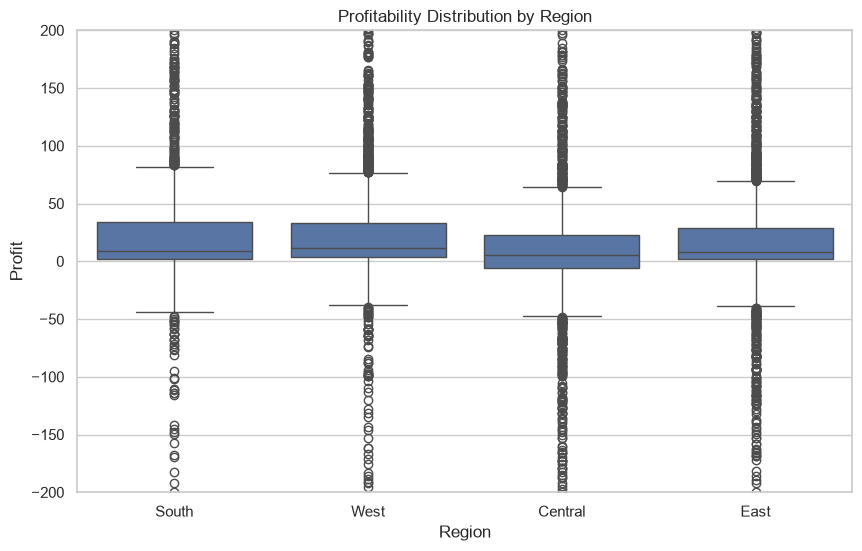

In [10]:
regions = df['Region'].unique()
region_data = [df[df['Region'] == r]['Profit'] for r in regions]
f_stat, p_val_anova = stats.f_oneway(*region_data)
print(f"--- ANOVA Results for Regions ---")
print(f"F-Statistic: {f_stat:.4f}")
print(f"P-Value: {p_val_anova:.4f}")
plt.figure(figsize=(10, 6))
sns.boxplot(x='Region', y='Profit', data=df)
plt.ylim(-200, 200)
plt.title('Profitability Distribution by Region')
plt.show()

--- contingency table ---
Ship Mode        First Class  Same Day  Second Class  Standard Class
Category                                                            
Furniture                327       119           427            1248
Office Supplies          910       326          1152            3638
Technology               301        98           366            1082

--- chi-square Results ---
chi-square Statistic: 3.5789
p-value: 0.7334


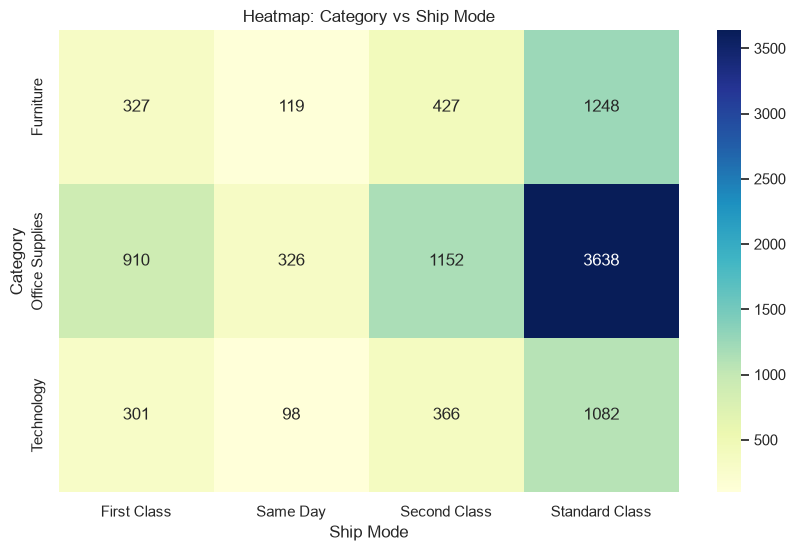

In [11]:
contingency_table = pd.crosstab(df['Category'], df['Ship Mode'])
print("--- contingency table ---")
print(contingency_table)
chi2, p_val_chi, dof, expected = stats.chi2_contingency(contingency_table)
print(f"\n--- chi-square Results ---")
print(f"chi-square Statistic: {chi2:.4f}")
print(f"p-value: {p_val_chi:.4f}")
plt.figure(figsize=(10,6))
sns.heatmap(contingency_table, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Heatmap: Category vs Ship Mode')
plt.show()

--- Tukey HSD Test Results ---
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1 group2 meandiff p-adj   lower    upper  reject
------------------------------------------------------
Central   East  15.0431 0.0986  -1.7808  31.867  False
Central  South   11.765 0.4065   -7.714  31.244  False
Central   West  16.7563  0.043   0.3566 33.1561   True
   East  South  -3.2781 0.9697  -22.005 15.4487  False
   East   West   1.7132  0.992 -13.7857 17.2121  False
  South   West   4.9914 0.8975 -13.3553 23.3381  False
------------------------------------------------------

--- Two-Way ANOVA Table ---
                             sum_sq      df          F        PR(>F)
C(Region)              4.177774e+05     3.0   2.565728  5.276354e-02
C(Category)            5.884249e+06     2.0  54.206074  3.850540e-24
C(Region):C(Category)  2.884577e+05     6.0   0.885764  5.041872e-01
Residual               5.417896e+08  9982.0        NaN           NaN


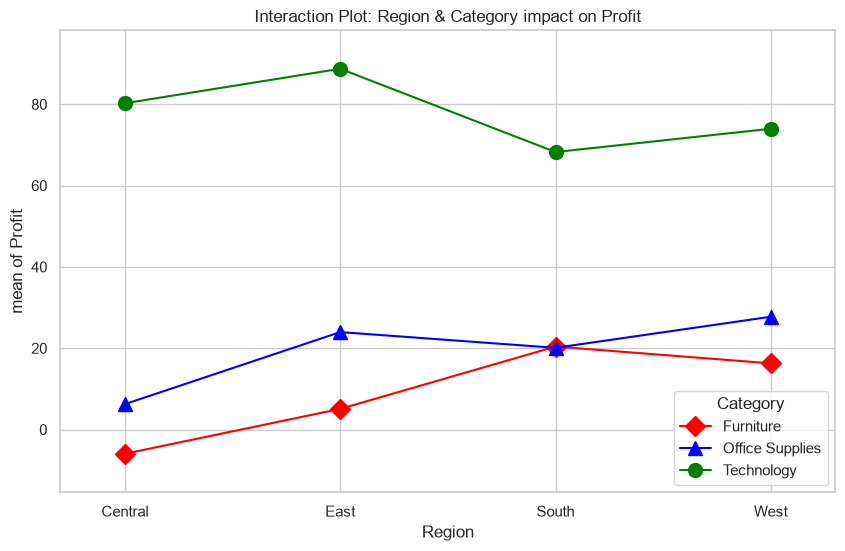

In [12]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(endog=df['Profit'], groups=df['Region'], alpha = 0.05)
print("--- Tukey HSD Test Results ---")
print(tukey)
model = ols('Profit ~ C(Region) + C(Category) + C(Region):C(Category)', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print("\n--- Two-Way ANOVA Table ---")
print(anova_table)
from statsmodels.graphics.factorplots import interaction_plot
fig, ax = plt.subplots(figsize=(10,6))
fig = interaction_plot(x=df['Region'], trace=df['Category'], response=df['Profit'],
                       colors=['red', 'blue', 'green'], markers=['D', '^', 'o'], ms=10, ax=ax)
plt.title('Interaction Plot: Region & Category impact on Profit')
plt.show()

--- Correlation Matrix ---
             Sales    Profit  Discount
Sales     1.000000  0.479064 -0.028190
Profit    0.479064  1.000000 -0.219487
Discount -0.028190 -0.219487  1.000000

--- Regression Model Summary ---
                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.272
Model:                            OLS   Adj. R-squared:                  0.272
Method:                 Least Squares   F-statistic:                     1866.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:08:00   Log-Likelihood:                -67126.
No. Observations:                9994   AIC:                         1.343e+05
Df Residuals:                    9991   BIC:                         1.343e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                   

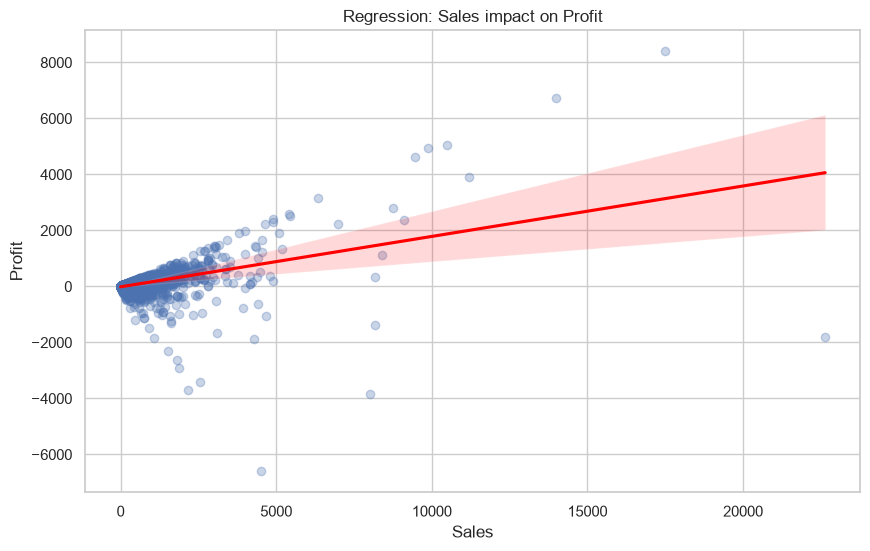

In [13]:
import statsmodels.api as sm
correlation_matrix = df[['Sales', 'Profit', 'Discount']].corr()
print("--- Correlation Matrix ---")
print(correlation_matrix)
X=df[['Sales', 'Discount']]
X=sm.add_constant(X)
y=df['Profit']
model = sm.OLS(y, X).fit()
print("\n--- Regression Model Summary ---")
print(model.summary())
plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Sales', y='Profit', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Regression: Sales impact on Profit')
plt.show()

In [14]:
new_data = [1, 2000, 0.10]
predicted_profit = model.predict(new_data)

print(f"Predicted Profit for this deal is: ${predicted_profit[0]:.2f}")

Predicted Profit for this deal is: $356.68



--- Confidence Intervals for Model Parameters ---
                   0           1
const      19.159279   29.454956
Sales       0.171590    0.184174
Discount -252.907716 -214.919033


C:\Users\varni\AppData\Roaming\Python\Python313\site-packages\pandas\plotting\_matplotlib\core.py:1680: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


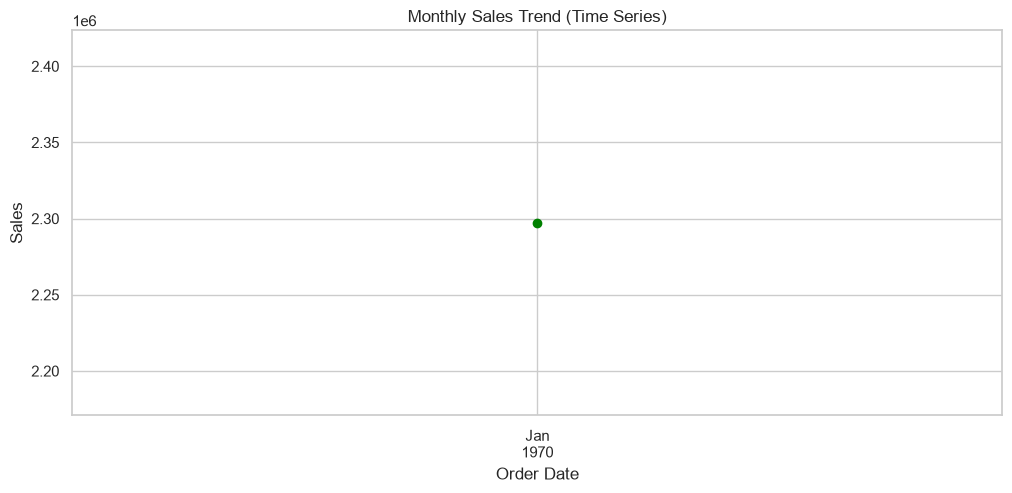

In [16]:
print("\n--- Confidence Intervals for Model Parameters ---")
print(model.conf_int())

df['Order Date'] = pd.to_datetime(df['Order Date'])
monthly_sales = df.resample('ME', on='Order Date')['Sales'].sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(color='green', marker='o')
plt.title('Monthly Sales Trend (Time Series)')
plt.ylabel('Sales')
plt.show()

In [17]:
data = df['Profit'].dropna()
mean = np.mean(data)
std_err = stats.sem(data)
h = std_err * stats.t.ppf((1+0.95)/ 2, len(data)-1)
print(f"We are 95% certain that the average trading volume for use is between:")
print(f"${mean - h:.2f}, ${mean + h:.2f}")

We are 95% certain that the average trading volume for use is between:
$24.06, $33.25


In [18]:
group_A = df[df['Region'] == 'East']['Profit']
group_B = df[df['Region'] == 'west']['Profit']
t_stat, p_val = stats.ttest_ind(group_A, group_B)
print(f"P-value for A/B Testing: {p_val:.4f}")
if p_val < 0.05:
  print("Decision: The new strategy in West has made a real difference, adopt it in the rest of the regions!")
else:
  print("Decision: There is no real difference; the new strategy has had no effect.")

P-value for A/B Testing: nan
Decision: There is no real difference; the new strategy has had no effect.


C:\Users\varni\AppData\Local\Temp\ipykernel_20944\4255856862.py:3: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_stat, p_val = stats.ttest_ind(group_A, group_B)


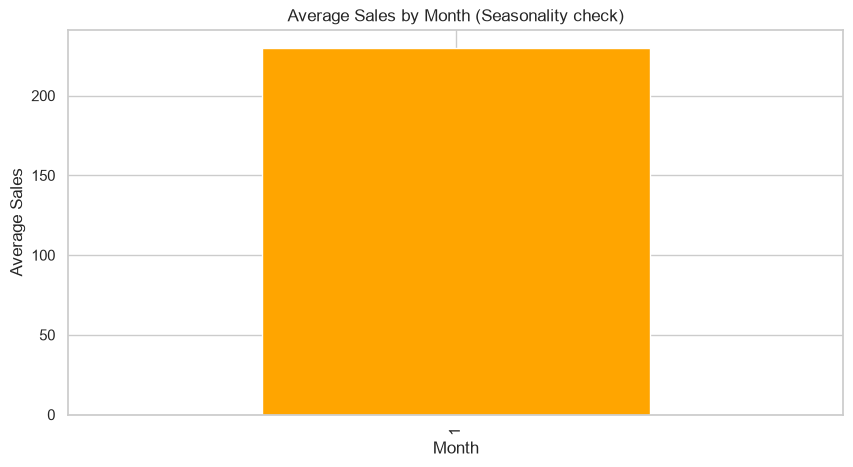

In [19]:
df['Month'] = df['Order Date'].dt.month
seasonal_impact = df.groupby('Month')['Sales'].mean()

plt.figure(figsize=(10, 5))
seasonal_impact.plot(kind='bar', color= 'orange')
plt.title('Average Sales by Month (Seasonality check)')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
# Select required columns
data = df[['Sales', 'Discount', 'Profit']].dropna().copy()

# Independent variables
X = data[['Sales', 'Discount']]

# Dependent variable
y = data['Profit']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (7995, 2)
Testing data shape: (1999, 2)


In [22]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Four machine learning models are ready!")

Four machine learning models are ready!


In [23]:
results = []
trained_models = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Evaluate model
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

    trained_models[name] = model

    print(f"\n{name}")
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))


Linear Regression
MAE: 66.14
RMSE: 287.41
R2 Score: -0.7037

Decision Tree
MAE: 37.66
RMSE: 221.1
R2 Score: -0.0082

Random Forest
MAE: 33.98
RMSE: 219.25
R2 Score: 0.0085

Gradient Boosting
MAE: 37.44
RMSE: 230.3
R2 Score: -0.0939


In [24]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
)

print("Machine Learning Model Comparison")
display(results_df)

Machine Learning Model Comparison


,Model,MAE,RMSE,R2 Score
2,Random Forest,33.984993,219.250606,0.008545
1,Decision Tree,37.657349,221.096723,-0.008222
3,Gradient Boosting,37.436555,230.299851,-0.093903
0,Linear Regression,66.138976,287.405697,-0.703657


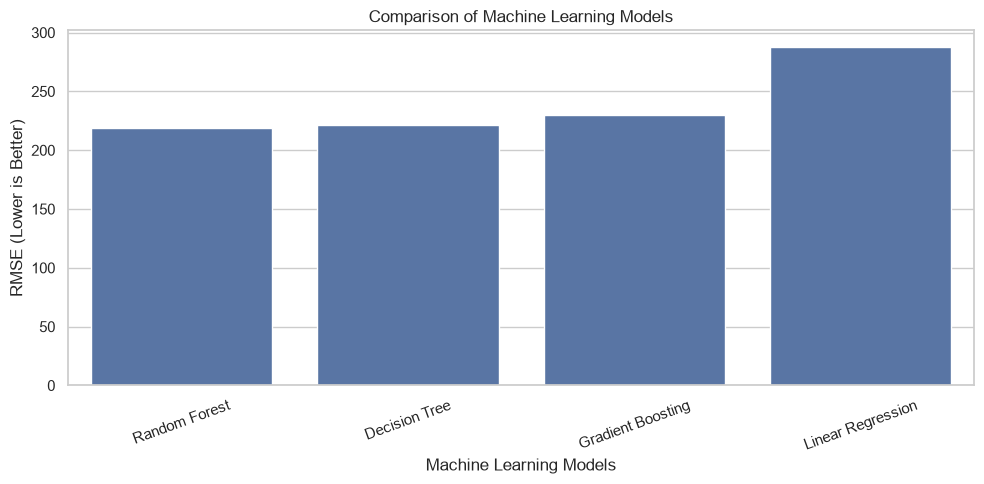

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title('Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('RMSE (Lower is Better)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [26]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)
print("Lowest RMSE:", results_df.iloc[0]['RMSE'])
print("R2 Score:", results_df.iloc[0]['R2 Score'])

Best Performing Model: Random Forest
Lowest RMSE: 219.25060562679258
R2 Score: 0.008544841106956746


In [27]:
results_df.to_excel(
    'ML_Model_Comparison.xlsx',
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!
